In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("data (4).csv")
data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [8]:
data = data.drop(columns=["id", "Unnamed: 32"], errors="ignore")
X = data.drop("diagnosis", axis=1).values
y = data["diagnosis"].map({"B":0,"M":1}).values

np.random.seed(42)
idx = np.random.permutation(len(X))
X = X[idx]
y = y[idx]

split = int(0.8*len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std==0]=1
X_train=(X_train-mean)/std
X_test=(X_test-mean)/std

In [9]:
weights=np.zeros(X_train.shape[1])
bias=0
lr=0.01
epochs=100

for _ in range(epochs):
    for i in range(len(X_train)):
        pred=1 if np.dot(X_train[i],weights)+bias>=0 else 0
        error=y_train[i]-pred
        weights+=lr*error*X_train[i]
        bias+=lr*error

In [5]:
pred=[]
for x in X_test:
    pred.append(1 if np.dot(x,weights)+bias>=0 else 0)
pred=np.array(pred)

TP=np.sum((pred==1)&(y_test==1))
TN=np.sum((pred==0)&(y_test==0))
FP=np.sum((pred==1)&(y_test==0))
FN=np.sum((pred==0)&(y_test==1))

accuracy=np.mean(pred==y_test)*100
precision=TP/(TP+FP) if TP+FP else 0
recall=TP/(TP+FN) if TP+FN else 0
f1=2*precision*recall/(precision+recall) if precision+recall else 0

print("Accuracy:",round(accuracy,2),"%")
print("Precision:",round(precision,4))
print("Recall:",round(recall,4))
print("F1 Score:",round(f1,4))

Accuracy: 92.98 %
Precision: 0.9149
Recall: 0.9149
F1 Score: 0.9149


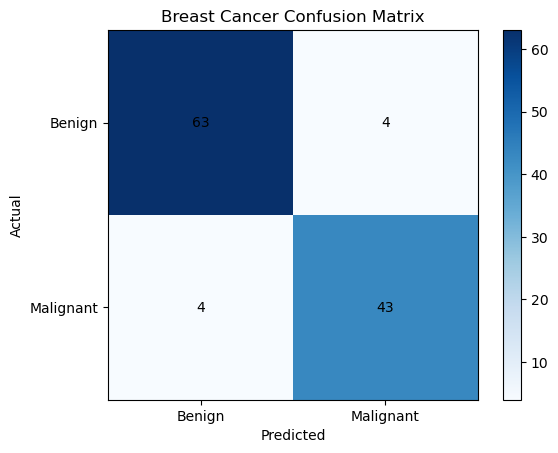

In [6]:
cm=np.array([[TN,FP],[FN,TP]])
plt.imshow(cm,cmap="Blues")
plt.title("Breast Cancer Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0,1],["Benign","Malignant"])
plt.yticks([0,1],["Benign","Malignant"])
for i in range(2):
    for j in range(2):
        plt.text(j,i,cm[i,j],ha="center",va="center")
plt.colorbar()
plt.show()